# EDA — Panoptic Indoor Segmentation v5

**Dataset:** `panoptic-indoor-segmentation` v5 (Roboflow, export 2024-04-09, lisensi CC BY 4.0)

**Lingkup:** 922 gambar · 11.845 anotasi · 75 kategori · 62,48 MB

**Tanggal pengerjaan:** 12 November 2026



## Setup

Berkas gambar dataset (62 MB) tidak di-commit ke repo, tetapi dataset-nya
tersedia publik:

https://universe.roboflow.com/panopticindoor/panoptic-indoor-segmentation/dataset/5

Unduh versi 5 dalam format COCO Segmentation, lalu letakkan folder `train/`,
`valid/`, `test/` beserta JSON COCO-nya.

Lokasi dataset ditentukan dengan urutan:

1. Variabel lingkungan `DATASET_DIR`, atau
2. pencarian ke atas dari direktori kerja sampai menemukan folder `train/`.

In [1]:
import os, sys, json, glob, hashlib, math
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
import cv2
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display


def find_up(start, marker):
    for c in [Path(start).resolve(), *Path(start).resolve().parents]:
        if (c / marker).exists():
            return c
    return None


_env = os.environ.get("DATASET_DIR")
if _env:
    DATA_ROOT = Path(_env).resolve()
    if not (DATA_ROOT / "train").is_dir():
        raise SystemExit(f"DATASET_DIR={DATA_ROOT} tidak berisi folder train/")
else:
    DATA_ROOT = find_up(Path.cwd(), "train")
    if DATA_ROOT is None:
        raise SystemExit(
            "Folder dataset tidak ditemukan. Set DATASET_DIR ke folder yang "
            "berisi train/, valid/, test/. Dataset dapat diunduh dari "
            "https://universe.roboflow.com/panopticindoor/"
            "panoptic-indoor-segmentation/dataset/5 (format COCO Segmentation)."
        )

SPLITS = ["train", "valid", "test"]
SEP = "=" * 78

print("data :", DATA_ROOT)
print("notebook ini tidak menulis berkas apa pun ke disk")

data : C:\Users\Rafli\Documents\kodin\python\kompis\Minggu 13
notebook ini tidak menulis berkas apa pun ke disk


## 1. Integritas data

Struktur JSON C0CO per split, lalu pemeriksaan silang antara berkas di disk dan
entri JSON: berkas hilang, berkas tanpa entri, duplikat id, anotasi yatim,
referensi kategori tak dikenal, dan gambar tanpa anotasi.

In [2]:
data, ann_files = {}, {}
for s in SPLITS:
    jp = glob.glob(os.path.join(DATA_ROOT, s, "*.json"))
    if len(jp) != 1:
        raise RuntimeError(f"{s}: expected 1 json, found {len(jp)}")
    with open(jp[0], encoding="utf-8") as f:
        data[s] = json.load(f)
    ann_files[s] = jp[0]

print("Struktur JSON per split:")
for s in SPLITS:
    d = data[s]
    print(f"  {s:5s} keys={sorted(d.keys())}  images={len(d.get('images', []))}  "
          f"annotations={len(d.get('annotations', []))}  categories={len(d.get('categories', []))}")

Struktur JSON per split:
  train keys=['annotations', 'categories', 'images', 'info', 'licenses']  images=397  annotations=4479  categories=75
  valid keys=['annotations', 'categories', 'images', 'info', 'licenses']  images=166  annotations=2022  categories=75
  test  keys=['annotations', 'categories', 'images', 'info', 'licenses']  images=359  annotations=5344  categories=75


In [3]:
consistency = []
for s in SPLITS:
    d = data[s]
    folder = os.path.join(DATA_ROOT, s)
    on_disk = {f for f in os.listdir(folder) if f.lower().endswith((".jpg", ".jpeg", ".png"))}
    declared = {im["file_name"] for im in d["images"]}
    missing = sorted(declared - on_disk)
    orphans = sorted(on_disk - declared)
    dup_ids = [k for k, v in Counter(im["id"] for im in d["images"]).items() if v > 1]
    dup_fnames = [k for k, v in Counter(im["file_name"] for im in d["images"]).items() if v > 1]
    ann_ids = [a["id"] for a in d["annotations"]]
    dup_ann = [k for k, v in Counter(ann_ids).items() if v > 1]
    img_ids = {im["id"] for im in d["images"]}
    orphan_ann = [a for a in d["annotations"] if a["image_id"] not in img_ids]
    cat_ids = {c["id"] for c in d["categories"]}
    bad_cat = [a for a in d["annotations"] if a["category_id"] not in cat_ids]
    no_ann_imgs = [im for im in d["images"] if im["id"] not in {a["image_id"] for a in d["annotations"]}]
    consistency.append(dict(
        split=s, on_disk=len(on_disk), declared=len(declared),
        missing_files=len(missing), orphan_files=len(orphans),
        dup_image_ids=len(dup_ids), dup_filenames=len(dup_fnames),
        dup_ann_ids=len(dup_ann), orphan_annotations=len(orphan_ann),
        bad_category_refs=len(bad_cat), images_without_annotations=len(no_ann_imgs),
    ))
    if missing:
        print(f"  [{s}] file hilang: {missing[:5]}")
    if orphans:
        print(f"  [{s}] file tanpa entri JSON: {orphans[:5]}")
    if no_ann_imgs:
        print(f"  [{s}] gambar tanpa anotasi: {len(no_ann_imgs)} -> {[i['file_name'] for i in no_ann_imgs][:5]}")

cons_df = pd.DataFrame(consistency)
print(cons_df.to_string(index=False))

  [valid] gambar tanpa anotasi: 1 -> ['182169175_jpg.rf.a8d223203fc5bd311086fdf38e40eb0a.jpg']


split  on_disk  declared  missing_files  orphan_files  dup_image_ids  dup_filenames  dup_ann_ids  orphan_annotations  bad_category_refs  images_without_annotations
train      397       397              0             0              0              0            0                   0                  0                           0
valid      166       166              0             0              0              0            0                   0                  0                           1
 test      359       359              0             0              0              0            0                   0                  0                           0


In [4]:
print("--- Kategori ---")
all_cats = {}
for s in SPLITS:
    for c in data[s]["categories"]:
        all_cats.setdefault(c["id"], c["name"])
print(f"  id unik: {len(all_cats)}")
name_counter = Counter(all_cats.values())
print(f"  nama duplikat: {[k for k, v in name_counter.items() if v > 1]}")
per_split_names = {s: {c["name"] for c in data[s]["categories"]} for s in SPLITS}
print(f"  kategori tidak konsisten antar split: "
      f"{set.union(*per_split_names.values()) - set.intersection(*per_split_names.values())}")

--- Kategori ---
  id unik: 75
  nama duplikat: []
  kategori tidak konsisten antar split: set()


**Integritas struktural baik.** Masalahnya ada di isi, bukan di referensi.
Satu-satunya temuan: satu gambar `valid` tanpa anotasi.

## 2. Properti gambar

Membaca 922 berkas: resolusi, ukuran, mode, EXIF, kecerahan, kontras, blur,
saturasi. Ini yang mengungkap bahwa `test` punya populasi resolusi berbeda.

In [5]:
img_rows = []
for s in SPLITS:
    folder = os.path.join(DATA_ROOT, s)
    for im in data[s]["images"]:
        p = os.path.join(folder, im["file_name"])
        if not os.path.exists(p):
            continue
        size_bytes = os.path.getsize(p)
        with Image.open(p) as pil:
            pil.load()
            fmt = pil.format
            mode = pil.mode
            exif_n = len(pil.getexif()) if hasattr(pil, "getexif") else 0
            orientation = None
            try:
                orientation = pil.getexif().get(274)
            except Exception:
                pass
            arr = np.asarray(pil.convert("RGB"))
        gray = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
        bright = float(gray.mean())
        contrast = float(gray.std())
        blur = float(cv2.Laplacian(gray, cv2.CV_64F).var())
        sat = float(cv2.cvtColor(arr, cv2.COLOR_RGB2HSV)[:, :, 1].mean())
        w, h = im["width"], im["height"]
        img_rows.append(dict(
            split=s, file_name=im["file_name"], id=im["id"],
            w=w, h=h, real_w=arr.shape[1], real_h=arr.shape[0],
            declared_mismatch=int((w, h) != (arr.shape[1], arr.shape[0])),
            mp=round(w * h / 1e6, 3), aspect=round(w / h, 3),
            bytes=size_bytes, kb=round(size_bytes / 1024, 1),
            fmt=fmt, mode=mode, exif_tags=exif_n, orientation=orientation,
            brightness=round(bright, 1), contrast=round(contrast, 1),
            blur_var=round(blur, 1), saturation=round(sat, 1),
        ))
imgs = pd.DataFrame(img_rows)
print(f"gambar terbaca: {len(imgs)}")
imgs.groupby("split")[["w", "h", "mp", "kb", "brightness", "contrast", "blur_var"]].describe().round(1)

gambar terbaca: 922


w                                                         h         \
       count   mean    std    min    25%    50%     75%     max  count   mean   
split                                                                           
test   359.0  838.8  474.8  190.0  558.0  750.0  1000.0  3143.0  359.0  718.9   
train  397.0  643.9   25.3  561.0  640.0  640.0   640.0   857.0  397.0  489.3   
valid  166.0  644.0   26.7  640.0  640.0  640.0   640.0   857.0  166.0  489.2   

       ... contrast       blur_var                                      \
       ...      75%   max    count    mean     std   min    25%    50%   
split  ...                                                               
test   ...     64.6  89.6    359.0  1246.3  1519.1  12.4  354.8  721.4   
train  ...     66.3  96.4    397.0   478.9   771.1  11.1  112.7  245.7   
valid  ...     67.7  91.3    166.0   477.9  1101.3  15.3  120.4  236.4   

                        
          75%      max  
split                   
test   1581.4  10807.2  
train   576.9   7962.8  
valid   556.6  13030.8  

[3 rows x 56 columns]

In [6]:
print("Resolusi (w x h) terbanyak:")
print(imgs.groupby(["w", "h"]).size().sort_values(ascending=False).head(12).to_string())
print(f"\nMismatch dimensi JSON vs file nyata: {imgs['declared_mismatch'].sum()}")
mm = imgs[imgs.declared_mismatch == 1]
if len(mm):
    print(mm[["split", "file_name", "w", "h", "real_w", "real_h"]].to_string(index=False))

print("\nStandarisasi resolusi per split (640x480 / lainnya):")
for s in SPLITS:
    sub = imgs[imgs.split == s]
    std = ((sub.w == 640) & (sub.h == 480)).sum()
    print(f"  {s:5s} 640x480: {std:3d}/{len(sub):3d} ({std/len(sub)*100:5.1f}%)  "
          f"rasio aspek 4:3: {(abs(sub.aspect - 4/3) < 0.02).sum():3d}  "
          f"median MP: {sub.mp.median():.2f}")

Resolusi (w x h) terbanyak:
w     h   
640   480     511
960   1280     31
640   640      29
750   500      24
225   225      13
275   183      12
720   1280      8
1024  1024      6
1500  1000      6
1200  800       5
720   480       5
800   800       4

Mismatch dimensi JSON vs file nyata: 4
split                                             file_name   w   h  real_w  real_h
train 182169107_jpg.rf.c9b1bbecf1474a5b36a6df197c30dfed.jpg 640 480     480     640
train 182169121_jpg.rf.eb0ccb71d0ea38adf1e38bf9c02a4a15.jpg 640 480     480     640
valid 182169109_jpg.rf.0531e60eb6e404d9633ed0c23a381fe7.jpg 640 480     480     640
valid 182169108_jpg.rf.205d9f1ed8f888006b8f97fc29eb8790.jpg 640 480     480     640

Standarisasi resolusi per split (640x480 / lainnya):
  train 640x480: 359/397 ( 90.4%)  rasio aspek 4:3: 365  median MP: 0.31
  valid 640x480: 152/166 ( 91.6%)  rasio aspek 4:3: 153  median MP: 0.31
  test  640x480:   0/359 (  0.0%)  rasio aspek 4:3:  30  median MP: 0.48


In [7]:
print(f"EXIF tag count: min={imgs['exif_tags'].min()} max={imgs['exif_tags'].max()} "
      f"median={imgs['exif_tags'].median()}")
print(f"Gambar dengan EXIF kosong: {(imgs['exif_tags'] == 0).sum()} / {len(imgs)}")
print(f"Gambar dengan sisi < 640 px: {((imgs.w < 640) | (imgs.h < 640)).sum()}")
print(f"Gambar dengan sisi < 200 px: {((imgs.w < 200) | (imgs.h < 200)).sum()}")
print(f"Gambar > 2 MP: {(imgs.mp > 2).sum()}")
print(f"Aspect ratio: min={imgs.aspect.min():.2f} max={imgs.aspect.max():.2f} "
      f"median={imgs.aspect.median():.2f}")
print(f"Brightness <60 (gelap): {(imgs.brightness < 60).sum()} | "
      f"60-100: {((imgs.brightness >= 60) & (imgs.brightness < 100)).sum()} | "
      f">=100: {(imgs.brightness >= 100).sum()}")
print(f"Blur var <50 (buram): {(imgs.blur_var < 50).sum()} | <100: {(imgs.blur_var < 100).sum()}")
print("\nPer split, brightness & blur (median):")
print(imgs.groupby("split")[["brightness", "blur_var", "mp"]].median().round(1).to_string())

EXIF tag count: min=0 max=0 median=0.0
Gambar dengan EXIF kosong: 922 / 922
Gambar dengan sisi < 640 px: 726
Gambar dengan sisi < 200 px: 37
Gambar > 2 MP: 19
Aspect ratio: min=0.56 max=2.33 median=1.33
Brightness <60 (gelap): 21 | 60-100: 101 | >=100: 800
Blur var <50 (buram): 50 | <100: 142

Per split, brightness & blur (median):
       brightness  blur_var   mp
split                           
test        139.3     721.4  0.5
train       142.4     245.7  0.3
valid       142.6     236.4  0.3


**Implikasi:** train & valid sudah dinormalisasi Roboflow ke 640×480 (90–92%),
`test` tidak sama sekali (0%). Evaluasi pada test akan mencampur gambar 149 px
dan 3398 px. Tanpa kebijakan resize eksplisit, mAP tidak sebanding antar-gambar
maupun antar-model.

## 3. Duplikat & kebocoran split

Tiga jalur bukti bahwa `test` bukan split acak dari pool yang sama:
md5 byte-identik, dHash near-duplicate, lalu pola nama berkas dan divergensi
distribusi kelas (KL).

In [8]:
md5 = {}
for s in SPLITS:
    for fn in sorted(os.listdir(os.path.join(DATA_ROOT, s))):
        if not fn.lower().endswith((".jpg", ".jpeg", ".png")):
            continue
        p = os.path.join(DATA_ROOT, s, fn)
        h = hashlib.md5(open(p, "rb").read()).hexdigest()
        md5.setdefault(h, []).append(f"{s}/{fn}")
exact_dups = {k: v for k, v in md5.items() if len(v) > 1}
print(f"Grup duplikat byte-identik: {len(exact_dups)}")
for k, v in list(exact_dups.items())[:20]:
    print(f"  {v}")
cross_exact = {k: v for k, v in exact_dups.items()
               if len({x.split('/')[0] for x in v}) > 1}
print(f"Duplikat byte-identik LINTAS split (kebocoran): {len(cross_exact)}")

Grup duplikat byte-identik: 0
Duplikat byte-identik LINTAS split (kebocoran): 0


In [9]:
def dhash64(path, size=8):
    with Image.open(path) as pil:
        g = pil.convert("L").resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    v = 0
    for b in bits:
        v = (v << 1) | int(b)
    return v


paths, hashes, splits_of = [], [], []
for s in SPLITS:
    for fn in sorted(os.listdir(os.path.join(DATA_ROOT, s))):
        if not fn.lower().endswith((".jpg", ".jpeg", ".png")):
            continue
        paths.append(f"{s}/{fn}")
        hashes.append(dhash64(os.path.join(DATA_ROOT, s, fn)))
        splits_of.append(s)
hashes = np.array(hashes, dtype=np.uint64)
splits_of = np.array(splits_of)

near = []
for i in range(len(hashes)):
    x = np.bitwise_xor(hashes[i + 1:], hashes[i])
    d = np.array([bin(int(v)).count("1") for v in x]) if len(x) else np.array([])
    for j_off in np.where(d <= 6)[0]:
        j = i + 1 + j_off
        near.append((paths[i], paths[j], int(d[j_off])))
print(f"Pasangan near-duplicate (dHash <= 6 bit): {len(near)}")
cross_near = [p for p in near if p[0].split('/')[0] != p[1].split('/')[0]]
print(f"  di antaranya LINTAS split: {len(cross_near)}")
print(f"  dalam split yang sama: {len(near) - len(cross_near)}")
for p in sorted(near, key=lambda x: x[2])[:20]:
    tag = "LINTAS" if p[0].split('/')[0] != p[1].split('/')[0] else "dalam "
    print(f"    [{tag}] {p[0]} <-> {p[1]} (jarak {p[2]})")

Pasangan near-duplicate (dHash <= 6 bit): 10
  di antaranya LINTAS split: 3
  dalam split yang sama: 7
    [LINTAS] train/182169107_jpg.rf.c9b1bbecf1474a5b36a6df197c30dfed.jpg <-> test/114_jpeg.rf.bdf757579a02c0e1f1035f14d15a3890.jpg (jarak 0)
    [LINTAS] train/182169171_jpg.rf.86d6a58acc7813643e19951675bb9dfa.jpg <-> test/227_jpeg.rf.a654dd3ada8fbf4517fcde606e725e69.jpg (jarak 0)
    [dalam ] test/206_jpg.rf.8e4cf9e27323d69e54ea87c81711f61f.jpg <-> test/220_jpg.rf.e199956bb7b64d702dc77f274f0f6251.jpg (jarak 0)
    [dalam ] train/182169176_jpg.rf.78ee02ed76609d0a5941d9bcaa8b4136.jpg <-> train/182169178_jpg.rf.8d939433d5d5afd22a888556dc3c64cd.jpg (jarak 1)
    [LINTAS] train/182169179_jpg.rf.4b645d23a7fc18ba8cb189121f9defea.jpg <-> test/067_jpg.rf.801eea7616802e3c228071a814ebaebe.jpg (jarak 1)
    [dalam ] test/091_jpg.rf.e316184e643a000e5d907124608d5174.jpg <-> test/293_jpg.rf.95b96295149575dbd8716d9b4a1e480d.jpg (jarak 1)
    [dalam ] valid/182169532_jpg.rf.86aa1944cc2a861312ee55ebf6

In [10]:
print("Asal-usul split (pola nama berkas):")
for s in SPLITS:
    names = [im["file_name"] for im in data[s]["images"]]
    num = sum(1 for n in names if n.split("_")[0].isdigit())
    print(f"{s:5s} n={len(names)} prefix numerik={num} contoh={names[:3]}")
    print(f"      pola id numerik: min={min(int(n.split('_')[0]) for n in names if n.split('_')[0].isdigit())} "
          f"max={max(int(n.split('_')[0]) for n in names if n.split('_')[0].isdigit())}")
    print(f"      ekstensi asli pada nama: {Counter(n.split('.')[0].split('_')[-1] for n in names)}")

Asal-usul split (pola nama berkas):
train n=397 prefix numerik=396 contoh=['182169490_jpg.rf.fcd18e3f17da55609a792b9b5a2b9b5a.jpg', '182169482_jpg.rf.fe13b773f459205efc7071c324b0d194.jpg', '182169153_jpg.rf.ff12b6fd88ef817c5f53fff2d624aed1.jpg']
      pola id numerik: min=1 max=182169580
      ekstensi asli pada nama: Counter({'jpg': 388, 'png': 9})
valid n=166 prefix numerik=166 contoh=['182169305_jpg.rf.129f9b38aca39db06cd84fa3ede1b344.jpg', '182169405_jpg.rf.0aef31bb4fa63cae6ae732f1295c92a8.jpg', '182169427_jpg.rf.116d3df82ec4c1bfb80e95483f4df4a7.jpg']
      pola id numerik: min=274 max=182169579
      ekstensi asli pada nama: Counter({'jpg': 163, 'png': 3})
test  n=359 prefix numerik=358 contoh=['114_jpeg.rf.bdf757579a02c0e1f1035f14d15a3890.jpg', '099_jpg.rf.adfa2556136b57bb92d9d42ac345513e.jpg', '346_jpg.rf.c19951ec89774ceca284693d02206915.jpg']
      pola id numerik: min=1 max=360
      ekstensi asli pada nama: Counter({'jpg': 289, 'jpeg': 62, 'png': 8})


### 3.1 Divergensi distribusi kelas

KL divergence mengukur seberapa jauh proporsi kelas di `test`/`valid` menyimpang
dari `train`. Angkanya dipakai sebagai bukti kuantitatif, bukan kesan visual.

In [11]:
cats = {c["id"]: c["name"] for c in data["train"]["categories"]}

ann_rows = []
for s in SPLITS:
    d = data[s]
    img_by_id = {im["id"]: im for im in d["images"]}
    cat_name = {c["id"]: c["name"] for c in d["categories"]}
    for a in d["annotations"]:
        im = img_by_id.get(a["image_id"])
        if im is None:
            continue
        w, h = im["width"], im["height"]
        seg = a.get("segmentation")
        seg_type = "none"
        poly_area = 0.0
        n_poly = 0
        n_pts = 0
        degenerate = 0
        if isinstance(seg, list):
            seg_type = "polygon"
            n_poly = len(seg)
            for poly in seg:
                pts = np.array(poly, dtype=float).reshape(-1, 2)
                n_pts += len(pts)
                if len(pts) < 3:
                    degenerate += 1
                    continue
                x, y = pts[:, 0], pts[:, 1]
                poly_area += abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1))) / 2
        elif isinstance(seg, dict):
            seg_type = "rle"
        x, y, bw, bh = a["bbox"]
        bbox_area = bw * bh
        ann_rows.append(dict(
            split=s, image_id=a["image_id"], file_name=im["file_name"],
            category_id=a["category_id"], category=cat_name.get(a["category_id"], "?"),
            iscrowd=a.get("iscrowd", 0), seg_type=seg_type,
            n_poly=n_poly, n_pts=n_pts, degenerate_poly=degenerate,
            bx=x, by=y, bw=bw, bh=bh, bbox_area=bbox_area,
            rel_bbox=bbox_area / (w * h), rel_mask=min(poly_area, w * h) / (w * h),
            bbox_aspect=(bw / bh) if bh else np.nan,
            oob=int(x < 0 or y < 0 or x + bw > w + 1 or y + bh > h + 1),
            degenerate_bbox=int(bw <= 0 or bh <= 0),
            img_w=w, img_h=h,
        ))
anns = pd.DataFrame(ann_rows)
print(f"Total anotasi terbaca: {len(anns)}")

Total anotasi terbaca: 11845


In [12]:
cls = anns.pivot_table(index="category", columns="split", values="image_id",
                       aggfunc="size", fill_value=0)
cls = cls.reindex(columns=SPLITS, fill_value=0)
cls = cls.reindex(index=sorted(cats.values()), fill_value=0)
cls["total"] = cls.sum(axis=1)
cls = cls.sort_values("total", ascending=False)

prop = cls[cls["total"] > 0][SPLITS].div(cls[cls["total"] > 0][SPLITS].sum(), axis=1) + 1e-9
kl_tr_te = float((prop["train"] * np.log(prop["train"] / prop["test"])).sum())
kl_tr_va = float((prop["train"] * np.log(prop["train"] / prop["valid"])).sum())
print(f"KL(train || test) = {kl_tr_te:.3f}")
print(f"KL(train || valid) = {kl_tr_va:.3f}")

KL(train || test) = 0.801
KL(train || valid) = 0.135


In [13]:
stable = cls[(cls["train"] >= 10) & (cls["test"] >= 1)].index
ratio = (prop.loc[stable, "test"] / prop.loc[stable, "train"]).sort_values()
print(f"Kelas (train>=10, muncul di test) yang paling berubah proporsinya — {len(ratio)} kelas")
show = pd.concat([ratio.head(6), ratio.tail(4)])
print(pd.concat([show.round(3).rename("rasio"), cls.loc[show.index, ["train", "test"]]], axis=1).to_string())

print("\nKelas yang HILANG sama sekali di test:")
gone = cls[(cls["train"] > 0) & (cls["test"] == 0)]
print(gone[["train", "valid", "test"]].to_string())

Kelas (train>=10, muncul di test) yang paling berubah proporsinya — 41 kelas
                   rasio  train  test
category                             
box                0.009     95     1
wallet             0.021    197     5
trash-bin          0.022    153     4
stairs             0.029    175     6
fire-extinguisher  0.116     29     4
pan                0.127    225    34
book               2.786    105   349
couch              3.492     18    75
cup                4.392     25   131
light              6.030     41   295

Kelas yang HILANG sama sekali di test:
split        train  valid  test
category                       
remote           9      1     0
shelf            2      4     0
wall             2      0     0
st-              1      0     0
tree-merged      1      0     0


**Implikasi metodologis:** skor pada "test set asli" **bukan** murni ukuran
generalisasi model — ia mencampur perbedaan sumber data, gaya anotasi, dan
resolusi. Harus dilaporkan sebagai *cross-source transfer*, bukan domain shift
murni. Domain shift sebenarnya baru terukur bersih pada test set buatan sendiri
(40 foto HP).

## 4. Statistik anotasi

Jumlah instance, tipe segmentation, `iscrowd`, bucket ukuran COCO, luas mask
relatif, dan kualitas geometri mask.

In [14]:
print("Tipe segmentation:")
print(anns.groupby(["split", "seg_type"]).size().to_string())
print(f"\niscrowd: {anns.iscrowd.sum()} ({anns.iscrowd.mean()*100:.2f}%)")
print(f"Degenerate bbox (w/h <= 0): {anns.degenerate_bbox.sum()}")
print(f"Bbox keluar batas gambar: {anns.oob.sum()}")
print(f"Poligon < 3 titik: {anns.degenerate_poly.sum()}")
print(f"Anotasi tanpa segmentation: {(anns.seg_type == 'none').sum()}")

Tipe segmentation:
split  seg_type
test   polygon     5344
train  polygon     4479
valid  polygon     2022

iscrowd: 0 (0.00%)
Degenerate bbox (w/h <= 0): 0
Bbox keluar batas gambar: 0
Poligon < 3 titik: 0
Anotasi tanpa segmentation: 0


In [15]:
per_img = anns.groupby(["split", "image_id"]).size()
print("Instance per gambar:")
for s in SPLITS:
    v = per_img.loc[s] if s in per_img.index.get_level_values(0) else pd.Series(dtype=int)
    print(f"  {s:5s} n={len(v):3d} mean={v.mean():5.1f} median={v.median():5.1f} "
          f"max={v.max():3d} p95={np.percentile(v, 95):5.1f}")

Instance per gambar:
  train n=397 mean= 11.3 median=  8.0 max= 61 p95= 29.2
  valid n=165 mean= 12.3 median=  9.0 max= 79 p95= 32.8
  test  n=359 mean= 14.9 median= 12.0 max=129 p95= 34.2


In [16]:
def bucket(a):
    if a < 32 ** 2:
        return "small <32^2"
    if a < 96 ** 2:
        return "medium <96^2"
    return "large >=96^2"


anns["coco_bucket"] = anns.bbox_area.apply(bucket)
print("Bucket ukuran COCO (luas bbox):")
print(anns.groupby(["split", "coco_bucket"]).size().unstack(fill_value=0).to_string())


def relb(r):
    if r < 0.001:
        return "1 <0.1%"
    if r < 0.01:
        return "2 0.1-1%"
    if r < 0.05:
        return "3 1-5%"
    if r < 0.2:
        return "4 5-20%"
    return "5 >=20%"


anns["rel_bucket"] = anns.rel_mask.apply(relb)
print("\nBucket ukuran relatif terhadap luas gambar:")
print(anns.groupby(["split", "rel_bucket"]).size().unstack(fill_value=0).to_string())
print("\nDistribusi rel_mask:")
print(anns.rel_mask.describe(percentiles=[.05, .25, .5, .75, .95]).round(4).to_string())

Bucket ukuran COCO (luas bbox):
coco_bucket  large >=96^2  medium <96^2  small <32^2
split                                               
test                 3064          1706          574
train                2578          1407          494
valid                1148           679          195

Bucket ukuran relatif terhadap luas gambar:
rel_bucket  1 <0.1%  2 0.1-1%  3 1-5%  4 5-20%  5 >=20%
split                                                  
test            461      1680    1692     1098      413
train           223      1225    1345     1139      547
valid            82       566     627      529      218

Distribusi rel_mask:
count    11845.0000
mean         0.0699
std          0.1228
min          0.0000
5%           0.0008
25%          0.0052
50%          0.0212
75%          0.0777
95%          0.3012
max          0.9989


In [17]:
rows = []
for s in SPLITS:
    cat = {c["id"]: c["name"] for c in data[s]["categories"]}
    im_by = {im["id"]: im for im in data[s]["images"]}
    for a in data[s]["annotations"]:
        im = im_by[a["image_id"]]
        polys = a["segmentation"]
        n_poly = len(polys)
        n_pts = sum(len(p) // 2 for p in polys)
        area = 0.0
        for p in polys:
            pts = np.array(p, float).reshape(-1, 2)
            x, y = pts[:, 0], pts[:, 1]
            area += abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1))) / 2
        rows.append(dict(split=s, cat=cat[a["category_id"]], n_poly=n_poly, n_pts=n_pts,
                         mask_area=area, bbox_area=a["bbox"][2] * a["bbox"][3],
                         iw=im["width"], ih=im["height"],
                         bbox_aspect=a["bbox"][2] / a["bbox"][3] if a["bbox"][3] else np.nan))
k = pd.DataFrame(rows)
k["fill"] = (k.mask_area / k.bbox_area.replace(0, np.nan)).clip(0, 5)

print("Kualitas geometri mask (rasio luas mask / luas bbox = 'fill'):")
print(k.groupby("split")[["n_poly", "n_pts", "fill", "bbox_aspect"]]
      .describe(percentiles=[.5, .95, .99]).round(2).to_string())
print(f"\nAnotasi multi-poligon (>1 bagian): {(k.n_poly > 1).sum()} ({(k.n_poly > 1).mean()*100:.2f}%)")
print(f"Anotasi dengan >100 titik: {(k.n_pts > 100).sum()} ({(k.n_pts > 100).mean()*100:.2f}%)")
print(f"Anotasi dengan >500 titik: {(k.n_pts > 500).sum()}")
print(f"Mask mengisi >95% bbox: {(k.fill > 0.95).sum()}")
print(f"Mask mengisi <20% bbox (bentuk kompleks/berlubang): {(k.fill < 0.2).sum()}")
print(f"Bbox aspect ratio ekstrem (<0.2 atau >5): {((k.bbox_aspect < 0.2) | (k.bbox_aspect > 5)).sum()}")

Kualitas geometri mask (rasio luas mask / luas bbox = 'fill'):
       n_poly                                      n_pts                                                  fill                                          bbox_aspect                                           
        count mean  std  min  50%  95%  99%  max   count   mean    std  min   50%   95%     99%    max   count  mean   std   min   50%   95%   99%  max       count  mean   std   min   50%   95%   99%    max
split                                                                                                                                                                                                         
test   5344.0  1.0  0.0  1.0  1.0  1.0  1.0  1.0  5344.0  23.98  30.25  3.0  15.0  70.0  146.00  475.0  5344.0  0.64  0.18  0.02  0.65  0.92  0.98  1.0      5344.0  1.51  1.91  0.04  1.01  4.25  7.85  48.76
train  4479.0  1.0  0.0  1.0  1.0  1.0  1.0  1.0  4479.0  17.46  15.47  3.0  13.0  47.0   74.00  206.0  4479.

In [18]:
print("Total area relatif per gambar (indikasi tumpang tindih anotasi):")
for s in SPLITS:
    im_by = {im["id"]: im for im in data[s]["images"]}
    per = []
    for a in data[s]["annotations"]:
        im = im_by[a["image_id"]]
        area = 0.0
        for p in a["segmentation"]:
            pts = np.array(p, float).reshape(-1, 2)
            x, y = pts[:, 0], pts[:, 1]
            area += abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1))) / 2
        per.append((a["image_id"], area / (im["width"] * im["height"])))
    p = pd.DataFrame(per, columns=["image_id", "rel"])
    tot = p.groupby("image_id").rel.sum()
    print(f"  {s}: median={tot.median():.2f} p95={np.percentile(tot,95):.2f} max={tot.max():.2f} "
          f"gambar>1.5 (tumpang tindih berat)={int((tot>1.5).sum())}")

Total area relatif per gambar (indikasi tumpang tindih anotasi):
  train: median=0.95 p95=1.23 max=1.91 gambar>1.5 (tumpang tindih berat)=3
  valid: median=0.95 p95=1.21 max=1.43 gambar>1.5 (tumpang tindih berat)=0


  test: median=0.90 p95=1.16 max=1.74 gambar>1.5 (tumpang tindih berat)=1


In [19]:
def iou(a, b):
    x1, y1, w1, h1 = a
    x2, y2, w2, h2 = b
    ix = max(0, min(x1 + w1, x2 + w2) - max(x1, x2))
    iy = max(0, min(y1 + h1, y2 + h2) - max(y1, y2))
    inter = ix * iy
    u = w1 * h1 + w2 * h2 - inter
    return inter / u if u > 0 else 0


print("Duplikasi anotasi (kategori sama + bbox IoU > 0.85):")
for s in SPLITS:
    by = {}
    for a in data[s]["annotations"]:
        by.setdefault(a["image_id"], []).append(a)
    hits = []
    for iid, g in by.items():
        for i in range(len(g)):
            for j in range(i + 1, len(g)):
                if g[i]["category_id"] != g[j]["category_id"]:
                    continue
                v = iou(g[i]["bbox"], g[j]["bbox"])
                if v > 0.85:
                    hits.append((iid, g[i]["category_id"], round(v, 3)))
    print(f"  {s}: {len(hits)} pasangan")
    if hits[:5]:
        print(f"     contoh: {hits[:5]}")

Duplikasi anotasi (kategori sama + bbox IoU > 0.85):
  train: 10 pasangan
     contoh: [(5, 68, 0.989), (29, 68, 0.955), (73, 39, 0.994), (132, 15, 0.91), (152, 12, 0.878)]
  valid: 4 pasangan
     contoh: [(10, 6, 0.981), (20, 55, 0.995), (42, 61, 1.0), (55, 21, 0.966)]
  test: 18 pasangan
     contoh: [(41, 27, 1.0), (41, 27, 1.0), (52, 18, 0.875), (52, 18, 0.865), (54, 68, 0.999)]


## 5. Higiene kelas

Distribusi frekuensi kelas, ketidakseimbangan (Gini, entropi), kelas yang hilang
di tiap split, dan cacat penamaan.

In [20]:
print(f"Kelas dengan 0 anotasi (semua split): {sorted(cls.index[cls['total'] == 0])}")
print(f"Jumlah kelas dengan anotasi: {(cls['total'] > 0).sum()} / {len(cls)}")
nz = cls[cls["total"] > 0]["total"]
p = nz / nz.sum()
print(f"Top-10 kelas menguasai {p.head(10).sum()*100:.1f}% instance")
print(f"Kelas dengan <5 instance: {(nz < 5).sum()} | <10: {(nz < 10).sum()} | <50: {(nz < 50).sum()}")
srt = np.sort(nz.values)
gini = (2 * np.sum((np.arange(1, len(srt) + 1)) * srt) / (len(srt) * srt.sum())) - (len(srt) + 1) / len(srt)
print(f"Gini coefficient distribusi kelas: {gini:.3f}")
print(f"Shannon entropy: {-(p * np.log2(p)).sum():.2f} bit (maks {np.log2(len(p)):.2f})")

Kelas dengan 0 anotasi (semua split): ['indoor-objects']
Jumlah kelas dengan anotasi: 74 / 75
Top-10 kelas menguasai 52.8% instance
Kelas dengan <5 instance: 5 | <10: 14 | <50: 32
Gini coefficient distribusi kelas: 0.634
Shannon entropy: 5.13 bit (maks 6.21)


In [21]:
print("10 kelas terbanyak:")
print(cls.head(10)[["train", "valid", "test", "total"]].to_string())
print("\n15 kelas tersedikit (dengan anotasi):")
print(nz.sort_values().head(15).to_string())

print("\nKelas yang HILANG di salah satu split:")
for s in SPLITS:
    absent = [c for c in cls.index[cls["total"] > 0] if cls.loc[c, s] == 0]
    print(f"  {s}: {len(absent)} kelas -> {absent}")

10 kelas terbanyak:
split               train  valid  test  total
category                                     
wall-other-merged     756    315   650   1721
table-merged          319    134   258    711
person                192     90   413    695
chair                 217     67   353    637
floor-other-merged    261     92   239    592
book                  105     15   349    469
food-other-merged     127    108   149    384
light                  41     24   295    360
pan                   225     91    34    350
toy                   217     77    41    335

15 kelas tersedikit (dengan anotasi):
category
st-             1
tree-merged     1
scissor         2
hair drier      2
wall            2
toaster         5
shelf           6
teddy bear      6
scissors        6
wall-stone      6
flower          6
clock           7
keyboard        7
mouse           8
remote         10

Kelas yang HILANG di salah satu split:
  train: 9 kelas -> ['toothbrush', 'mouse', 'keyboard', 'flower', 'sci

In [22]:
print("Nama kelas mencurigakan (duplikat/terpotong/artefak):")
names = list(cls.index)
print(f"  mengandung 'merged': {[n for n in names if 'merged' in n]}")
print(f"  akhiran '-': {[n for n in names if n.endswith('-')]}")
print(f"  'indoor-objects': {'indoor-objects' in names}")
print(f"  mirror/duplikat semantik scissor: {[n for n in names if 'sciss' in n]}")

Nama kelas mencurigakan (duplikat/terpotong/artefak):
  mengandung 'merged': ['wall-other-merged', 'table-merged', 'floor-other-merged', 'food-other-merged', 'ceiling-merged', 'cabinet-merged', 'rug-merged', 'stove-merged', 'paper-merged', 'tree-merged']
  akhiran '-': ['st-']
  'indoor-objects': True
  mirror/duplikat semantik scissor: ['scissors', 'scissor']


Cacat penamaan yang tercatat:

- `scissor` (2) dan `scissors` (6) → duplikat semantik.
- `st-` (1) → nama terpotong. **Terverifikasi saat preprocessing:** mask-nya
  menutupi tangga lengkap dengan railing, jadi ini `stairs` yang terpotong
  namanya, bukan kelas baru.
- 10 kelas berakhiran `-merged` → indikasi beberapa instance digabung jadi satu region.
- `indoor-objects` → bukan kelas objek: ini **root supercategory** (id 0) yang
  diekspor Roboflow sebagai kategori; 74 kelas lain ber-`supercategory: indoor-objects`.

## 6. Stuff vs things

Hampir 40% anotasi bukan instance. Pemisahan ini menentukan metrik mana yang
sebanding dengan literatur COCO.

In [23]:
STUFF = {
    "wall", "wall-brick", "wall-stone", "wall-tile", "wall-wood", "wall-other-merged",
    "floor-other-merged", "floor-wood", "ceiling-merged", "rug-merged", "door-stuff",
    "mirror-stuff", "window-other", "window-blind", "curtain", "stairs", "tree-merged",
    "counter",
}
anns["is_stuff"] = anns.category.isin(STUFF)
print(anns.groupby(["split", "is_stuff"]).size().unstack(fill_value=0).to_string())
stuff_share = anns[anns.split == "train"].is_stuff.mean()
print(f"\nProporsi anotasi stuff di train: {stuff_share*100:.1f}%")
print(f"Kelas stuff terdeteksi: {sorted(set(anns[anns.is_stuff].category))}")
print("\nUkuran relatif mask: stuff vs things (median):")
print(anns.groupby("is_stuff")["rel_mask"].median().round(4).to_string())

is_stuff  False  True 
split                 
test       3472   1872
train      2694   1785
valid      1288    734

Proporsi anotasi stuff di train: 39.9%
Kelas stuff terdeteksi: ['ceiling-merged', 'counter', 'curtain', 'door-stuff', 'floor-other-merged', 'floor-wood', 'mirror-stuff', 'rug-merged', 'stairs', 'tree-merged', 'wall', 'wall-brick', 'wall-other-merged', 'wall-stone', 'wall-tile', 'wall-wood', 'window-blind', 'window-other']

Ukuran relatif mask: stuff vs things (median):
is_stuff
False    0.0146
True     0.0386


In [24]:
print("Gambar hanya berisi stuff / tanpa anotasi:")
for s in SPLITS:
    cat = {c["id"]: c["name"] for c in data[s]["categories"]}
    per = {}
    for a in data[s]["annotations"]:
        per.setdefault(a["image_id"], []).append(cat[a["category_id"]])
    empty = [im["file_name"] for im in data[s]["images"] if im["id"] not in per]
    only_stuff = [im["file_name"] for im in data[s]["images"]
                  if im["id"] in per and all(c in STUFF for c in per[im["id"]])]
    print(f"  {s:5s} tanpa anotasi={len(empty)} hanya-stuff={len(only_stuff)}")
    if empty:
        print(f"        {empty}")

Gambar hanya berisi stuff / tanpa anotasi:
  train tanpa anotasi=0 hanya-stuff=23
  valid tanpa anotasi=1 hanya-stuff=11
        ['182169175_jpg.rf.a8d223203fc5bd311086fdf38e40eb0a.jpg']
  test  tanpa anotasi=0 hanya-stuff=7


## 7. Ukuran objek, ko-okurensi, dan kecerahan

Tiga pemeriksaan yang dipakai untuk memilih kandidat analisis kegagalan:
kelas mana yang objeknya terkecil, kelas apa yang sering muncul bersama, dan
apakah kecerahan berkorelasi dengan kepadatan anotasi.

In [25]:
print("Ukuran objek per kelas (train) — kelas dengan objek TERKECIL:")
tr = anns[anns.split == "train"]
per_cls = tr.groupby("category").agg(
    n=("rel_mask", "size"),
    median_rel=("rel_mask", "median"),
    p10=("rel_mask", lambda x: np.percentile(x, 10)),
    median_bbox_w=("bw", "median"),
    median_bbox_h=("bh", "median"),
    frac_tiny=("rel_mask", lambda x: (x < 0.001).mean()),
).sort_values("median_rel")
print(per_cls.head(12).round(4).to_string())
print("\nKelas dengan objek TERBESAR:")
print(per_cls.tail(8).round(4).to_string())

Ukuran objek per kelas (train) — kelas dengan objek TERKECIL:
            n  median_rel     p10  median_bbox_w  median_bbox_h  frac_tiny
category                                                                  
remote      9      0.0017  0.0002         38.750        23.1250     0.3333
clock       3      0.0019  0.0007         27.500        27.5000     0.3333
knife      12      0.0022  0.0007         30.625        34.0625     0.4167
light      41      0.0028  0.0001         42.500        25.0000     0.2439
toy       217      0.0036  0.0008         46.250        45.6250     0.1613
spoon      35      0.0039  0.0009         55.000        55.6250     0.1429
book      105      0.0043  0.0009         47.500        63.1250     0.1524
cup        25      0.0051  0.0014         46.648        51.2500     0.0800
tv          2      0.0054  0.0049         47.500        38.4375     0.0000
vase        4      0.0059  0.0049         43.000        55.6250     0.0000
bottle     62      0.0062  0.0015     

In [26]:
print("Ko-okurensi kelas (train) — pasangan yang sering muncul bersama:")
sets = tr.groupby("image_id").category.apply(set)
pair = Counter()
for s_ in sets:
    for a, b in combinations(sorted(s_), 2):
        pair[(a, b)] += 1
for (a, b), c in pair.most_common(15):
    print(f"  {c:4d}  {a} + {b}")
print(f"Kelas unik per gambar: mean={sets.apply(len).mean():.1f} "
      f"median={sets.apply(len).median():.0f} max={sets.apply(len).max()}")
print(f"Gambar hanya berisi stuff: {sets.apply(lambda x: x.issubset(STUFF)).sum()}")

Ko-okurensi kelas (train) — pasangan yang sering muncul bersama:
   103  floor-other-merged + wall-other-merged
    74  table-merged + wall-other-merged
    69  stairs + wall-other-merged
    65  person + wall-other-merged
    56  floor-wood + wall-other-merged
    52  table-merged + wallet
    47  trash-bin + wall-other-merged
    46  ceiling-merged + wall-other-merged
    44  chair + wall-other-merged
    41  pan + stove-merged
    41  potted plant + wall-other-merged
    40  floor-other-merged + table-merged
    40  floor-other-merged + stairs
    39  door-stuff + wall-other-merged
    37  ceiling-merged + stairs
Kelas unik per gambar: mean=4.7 median=4 max=16
Gambar hanya berisi stuff: 23


In [27]:
print("Kecerahan vs jumlah anotasi:")
cnt = anns.groupby(["split", "image_id"]).size().rename("n_ann").reset_index()
cnt = cnt.rename(columns={"image_id": "id"})
m = imgs.merge(cnt, on=["split", "id"], how="left").fillna({"n_ann": 0})
for s in SPLITS:
    sub = m[m.split == s]
    r = np.corrcoef(sub.brightness, sub.n_ann)[0, 1] if len(sub) > 2 else float("nan")
    print(f"  {s:5s} korelasi(brightness, n_ann) = {r:+.3f}")
print("\nMedian anotasi per bucket kecerahan (semua split):")
m["b_bucket"] = pd.cut(m.brightness, [0, 60, 100, 150, 256],
                       labels=["<60", "60-100", "100-150", ">=150"])
print(m.groupby("b_bucket", observed=True)
      .agg(n_img=("n_ann", "size"), median_ann=("n_ann", "median")).to_string())

Kecerahan vs jumlah anotasi:
  train korelasi(brightness, n_ann) = -0.007
  valid korelasi(brightness, n_ann) = -0.183
  test  korelasi(brightness, n_ann) = -0.134

Median anotasi per bucket kecerahan (semua split):
          n_img  median_ann
b_bucket                   
<60          21        14.0
60-100      101         8.0
100-150     416        12.0
>=150       384         9.0


## 8. Anomali terverifikasi visual

Render overlay mask untuk kelas yang geometrinya mencurigakan. Empat anotasi
terbesar per kelas di split `train`, mask merah + bbox hijau. Semua montase
dirender di memori.

--- wallet : 4 anotasi terbesar ---


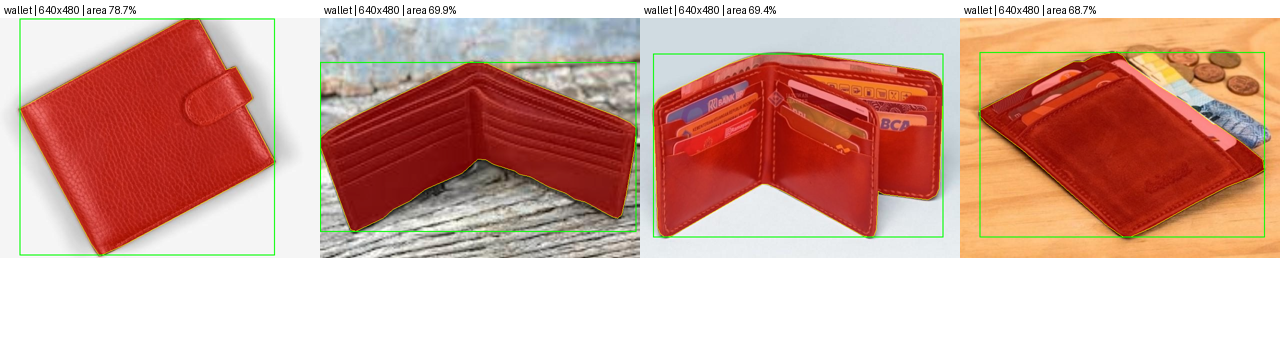

--- pan : 4 anotasi terbesar ---

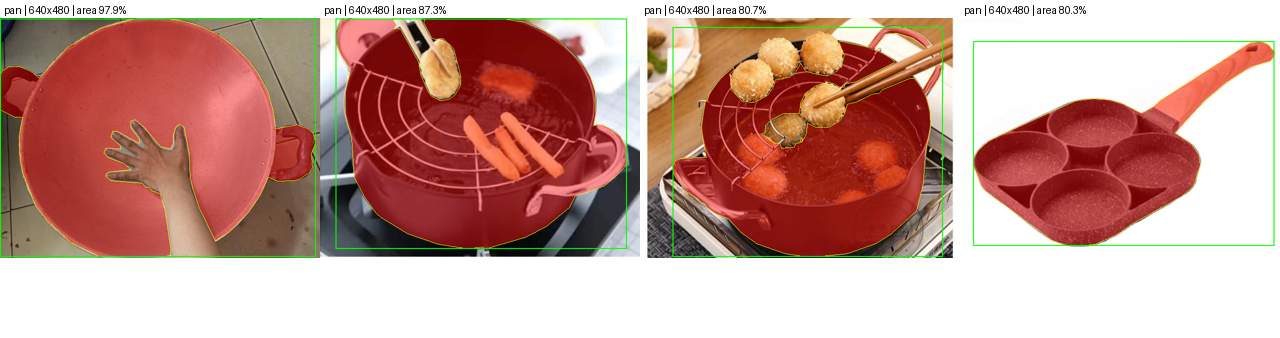

--- trash-bin : 4 anotasi terbesar ---


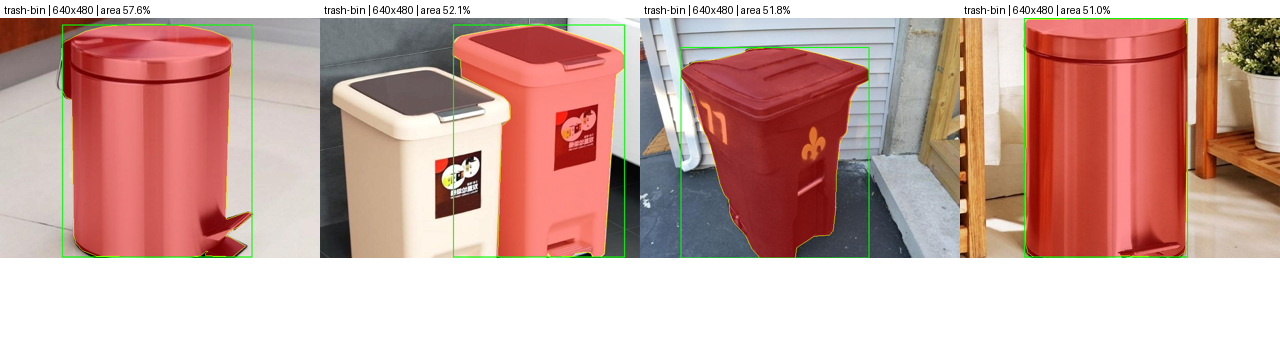

--- toy : 4 anotasi terbesar ---

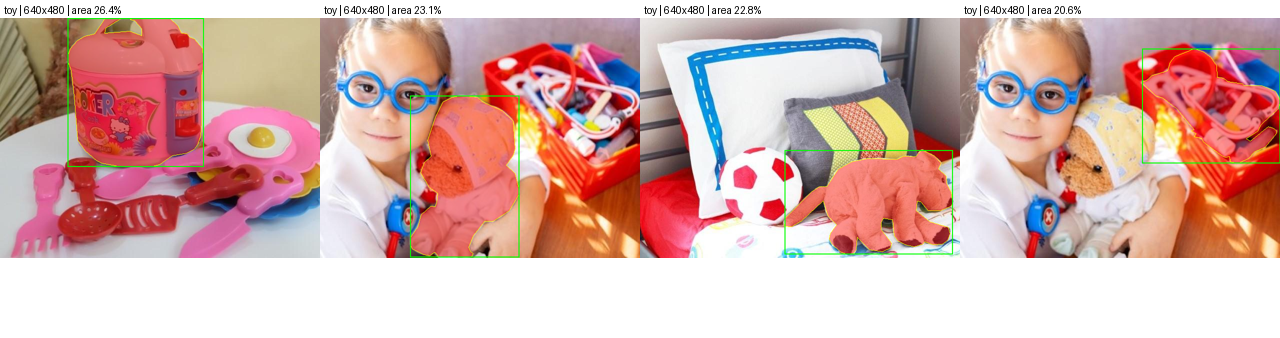

--- light : 4 anotasi terbesar ---


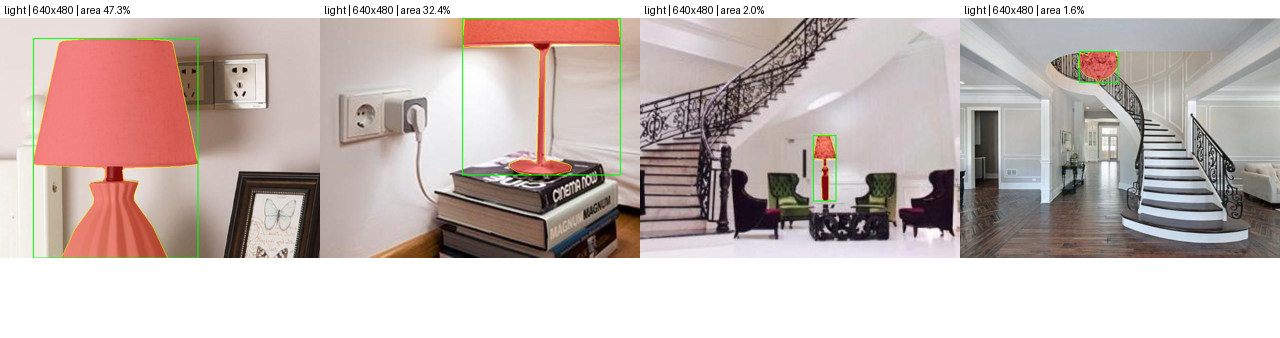

In [28]:
def render_montage(cells, title, size=320, pad_top=18):
    """Susun beberapa (PIL.Image, caption) menjadi satu kanvas di memori."""
    W = size * len(cells)
    H = size + pad_top
    canvas = Image.new("RGB", (W, H), (255, 255, 255))
    dr = ImageDraw.Draw(canvas)
    for i, (c, cap) in enumerate(cells):
        canvas.paste(c, (i * size, pad_top))
        dr.text((i * size + 4, 4), cap, fill=(0, 0, 0))
    return canvas


TARGETS = ["wallet", "pan", "trash-bin", "toy", "light"]
SIZE = 320

with open(glob.glob(os.path.join(DATA_ROOT, "train", "*.json"))[0], encoding="utf-8") as f:
    d_tr = json.load(f)
cat_tr = {c["id"]: c["name"] for c in d_tr["categories"]}
im_by_tr = {im["id"]: im for im in d_tr["images"]}
by_cls = {}
for a in d_tr["annotations"]:
    by_cls.setdefault(cat_tr[a["category_id"]], []).append(a)

for t in TARGETS:
    anns_t = sorted(by_cls.get(t, []), key=lambda a: a["bbox"][2] * a["bbox"][3], reverse=True)[:4]
    cells = []
    for a in anns_t:
        im = im_by_tr[a["image_id"]]
        p = os.path.join(DATA_ROOT, "train", im["file_name"])
        try:
            img = Image.open(p).convert("RGB")
        except Exception:
            continue
        sx = img.width / im["width"]
        sy = img.height / im["height"]
        overlay = Image.new("RGBA", img.size, (0, 0, 0, 0))
        dr = ImageDraw.Draw(overlay)
        for poly in a["segmentation"]:
            pts = np.array(poly, float).reshape(-1, 2)
            pts[:, 0] *= sx
            pts[:, 1] *= sy
            dr.polygon([tuple(q) for q in pts], fill=(255, 0, 0, 110),
                       outline=(255, 255, 0, 255))
        x, y, w, h = a["bbox"]
        dr.rectangle([x * sx, y * sy, (x + w) * sx, (y + h) * sy],
                     outline=(0, 255, 0, 255), width=2)
        out = Image.alpha_composite(img.convert("RGBA"), overlay).convert("RGB")
        out.thumbnail((SIZE, SIZE))
        cells.append((out, f"{t} | {im['width']}x{im['height']} | "
                           f"area {a['bbox'][2]*a['bbox'][3]/(im['width']*im['height'])*100:.1f}%"))
    if not cells:
        continue
    print(f"--- {t} : {len(cells)} anotasi terbesar ---")
    display(render_montage(cells, t))

In [29]:
print("Ukuran relatif bbox per kelas yang dicurigai salah label:")
for s in SPLITS:
    cat = {c["id"]: c["name"] for c in data[s]["categories"]}
    im_by = {im["id"]: im for im in data[s]["images"]}
    for target in ["wallet", "pan", "trash-bin"]:
        sel = []
        for a in data[s]["annotations"]:
            if cat[a["category_id"]] != target:
                continue
            im = im_by[a["image_id"]]
            sel.append(a["bbox"][2] * a["bbox"][3] / (im["width"] * im["height"]))
        if sel:
            print(f"{s:5s} {target:10s} n={len(sel):4d} median rel area={np.median(sel):.4f} "
                  f"max={max(sel):.3f} frac>5%={np.mean(np.array(sel)>0.05):.2f}")

Ukuran relatif bbox per kelas yang dicurigai salah label:
train wallet     n= 197 median rel area=0.1652 max=0.787 frac>5%=0.88
train pan        n= 225 median rel area=0.0983 max=0.979 frac>5%=0.63
train trash-bin  n= 153 median rel area=0.2287 max=0.576 frac>5%=0.94
valid wallet     n=  91 median rel area=0.1322 max=0.997 frac>5%=0.92
valid pan        n=  91 median rel area=0.0278 max=0.754 frac>5%=0.45
valid trash-bin  n=  70 median rel area=0.1943 max=0.538 frac>5%=0.90
test  wallet     n=   5 median rel area=0.1459 max=0.676 frac>5%=0.80
test  pan        n=  34 median rel area=0.0344 max=0.402 frac>5%=0.41
test  trash-bin  n=   4 median rel area=0.0183 max=0.658 frac>5%=0.25


### 8.1 Temuan per kelas

- **`wallet` — foto produk, bukan adegan indoor.** Mask menutupi 68–79% frame;
  objek adalah dompet studio dengan latar polos. 197 instance di train, median
  16,5% luas gambar, 88% >5%.
- **`pan` — close-up alat masak + adegan dapur.** 87% luas frame pada contoh
  terbesar. 225 instance train vs 34 test (rasio 0,127).
- **`trash-bin` — foto produk.** Mask 51–58% frame. 153 train vs 4 test.
- **`toy` — grup mainan, bukan instance tunggal.** Bbox mencakup satu set
  mainan utuh. Ini bukan anotasi instance dalam pengertian COCO; model akan
  belajar "region", bukan objek.
- **`light` — campuran lampu close-up dan lampu dalam adegan lebar; satu
  anotasi jelas salah.** Pada satu contoh, mask (blob) tidak menutupi lampu
  melainkan area dinding/tangga.
- **Duplikat visual.** Dua contoh `toy` adalah foto anak yang sama pada pose
  sama; dua contoh `light` adalah tangga yang sama pada zoom berbeda. Konsisten
  dengan 7 pasang near-duplicate dalam split.

**Kesimpulan:** dataset ini bukan murni "panoptic indoor scene". Ia mencampur
(a) adegan ruangan beranotasi panoptic, (b) foto objek close-up ala ImageNet,
dan (c) beberapa region gabungan. Ini menjelaskan 57,6% anotasi berukuran
`large` dan median luas 2,1%.

## 9. Tindakan perbaikan (wajib sebelum training)

| # | Tindakan | Alasan | Dampak |
|---|---|---|---|
| 1 | Perbaiki 4 gambar transposed (rotate 90° atau perbaiki JSON) | Koordinat di frame 640×480, file 480×640 → mask bergeser total | 2 train + 2 valid |
| 2 | Keluarkan 3 pasang near-duplicate lintas split dari test (atau dari train) | Kebocoran → skor test inflasi | 3 gambar test |
| 3 | Hapus `indoor-objects`; hapus `st-`; merge `scissor`→`scissors` | Kategori cacat | 74 → 72 kelas efektif |
| 4 | Tandai 18 kelas stuff terpisah; hitung AP things-only | 39,9% anotasi bukan instance | metrik sebanding literatur |
| 5 | Deduplikasi 10 (train) / 4 (valid) / 18 (test) anotasi kategori sama & bbox IoU>0.85 | Anotasi ganda | kecil tapi menggeser AP |
| 6 | Putuskan nasib `wallet`, `pan`, `trash-bin`, `toy` | Bukan instance ruangan; dominan di train, hampir hilang di test | `wallet`+`pan`+`trash-bin` = 575 anotasi train (12,8%) |
| 7 | Tetapkan kebijakan resize eksplisit untuk test (letterbox ke 640) | Test 149 px – 3398 px | mAP sebanding antar-gambar |
| 8 | Buang atau tandai 1 gambar valid tanpa anotasi | Tidak memberi sinyal | 1 gambar |

Catatan untuk #6: keputusan ini harus diambil **sebelum** split 5-fold dibuat,
karena mengubah komposisi kelas.

---

## 10. Implikasi untuk rencana eksperimen

1. **"Test set asli" harus dilaporkan sebagai cross-source transfer.** KL 0,80
   vs 0,14 membuktikan test bukan populasi yang sama.
2. **Efek domain shift bersih hanya terukur dari 40 foto sendiri.**
3. **AP things-only jadi metrik utama.** AP gabungan dilaporkan sebagai pelengkap.
4. **Kelas minoritas tidak boleh masuk rata-rata tanpa catatan.** 32 kelas <50
   instance; laporkan AP per kelompok frekuensi.
5. **3 kelas tersulit — pilihan berbasis data:** `remote` (9 instance, median
   luas 0,17%), `clock` (3, 0,19%), `knife` (12, 0,22%), `light` (41, 0,28%)
   sebagai kandidat keempat.
6. **Kandidat kegagalan sudah tersedia di awal:** objek tipis (828 bbox aspect
   ekstrem), objek sangat kecil (25% anotasi <0,52% luas), kelas tail, gambar
   test resolusi rendah (37 gambar <200 px).
7. **Arm scratch akan sangat tertekan** oleh 41 gambar yang hanya berisi stuff
   dan 1 gambar tanpa anotasi.
8. **Fold 5-fold wajib stratified per kelas**, karena 32 kelas <50 instance.

## 11. Gambar ekstrem: tergelap & terburam

Metrik blur dihitung ulang pada kanvas 640×480 agar tidak bias resolusi —
Laplacian variance bergantung pada ukuran gambar, sehingga gambar 3143 px
otomatis bernilai tinggi.

In [30]:
def metrics(rel):
    p = os.path.join(DATA_ROOT, rel)
    im = cv2.imread(p)
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    g = cv2.resize(g, (640, 480), interpolation=cv2.INTER_AREA)
    lap = cv2.Laplacian(g, cv2.CV_64F).var()
    sx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    sy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    sob = float(np.mean(np.hypot(sx, sy)))
    edge = float(np.mean(cv2.Canny(g, 100, 200) > 0) * 100)
    return lap, sob, edge


recs = []
for r in imgs.itertuples():
    rel = os.path.join(r.split, r.file_name)
    lap, sob, edge = metrics(rel)
    recs.append(dict(split=r.split, file_name=r.file_name, width=r.w, height=r.h,
                     brightness=r.brightness, contrast=r.contrast,
                     lap_norm=round(lap, 1), sobel=round(sob, 2), edge_pct=round(edge, 2)))
nm = pd.DataFrame(recs)

print(f"Median dataset: lap_norm={nm.lap_norm.median():.1f} sobel={nm.sobel.median():.2f} "
      f"edge%={nm.edge_pct.median():.2f}")
print(f"P10: lap_norm={nm.lap_norm.quantile(.1):.1f} sobel={nm.sobel.quantile(.1):.2f}")

Median dataset: lap_norm=337.2 sobel=42.89 edge%=4.92
P10: lap_norm=73.3 sobel=23.35


8 gambar tergelap:


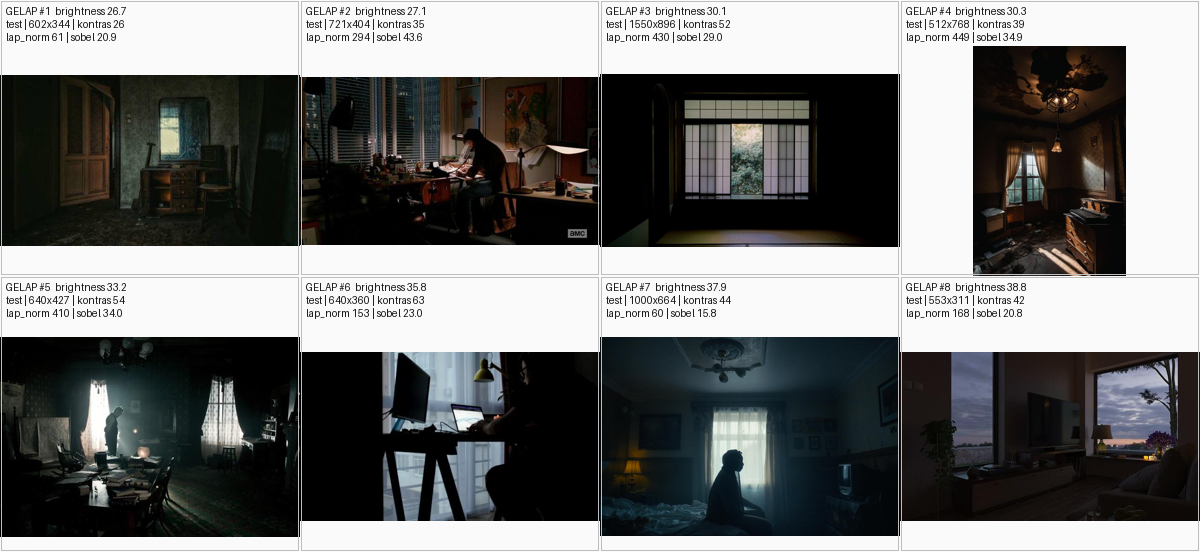

In [31]:
def montage(rows, title_fn, cols=4, cell=(300, 230), pad_top=46):
    """Susun montase di memori, kembalikan satu PIL.Image."""
    n = len(rows)
    nrows = (n + cols - 1) // cols
    canvas = Image.new("RGB", (cell[0] * cols, (cell[1] + pad_top) * nrows), (250, 250, 250))
    dr = ImageDraw.Draw(canvas)
    for i, r in enumerate(rows):
        cx, cy = (i % cols) * cell[0], (i // cols) * (cell[1] + pad_top)
        p = os.path.join(DATA_ROOT, r["split"], r["file_name"])
        im = Image.open(p).convert("RGB")
        im.thumbnail(cell)
        canvas.paste(im, (cx + (cell[0] - im.width) // 2,
                          cy + pad_top + (cell[1] - im.height) // 2))
        dr.rectangle([cx + 1, cy + 1, cx + cell[0] - 2, cy + cell[1] + pad_top - 2],
                     outline=(190, 190, 190))
        for j, line in enumerate(title_fn(r, i + 1)):
            dr.text((cx + 6, cy + 5 + j * 13), line, fill=(20, 20, 20))
    return canvas


dark = nm.nsmallest(8, "brightness").to_dict("records")
blur = nm.nsmallest(8, "lap_norm").to_dict("records")


def t_dark(r, k):
    return [f"GELAP #{k}  brightness {r['brightness']:.1f}",
            f"{r['split']} | {r['width']}x{r['height']} | kontras {r['contrast']:.0f}",
            f"lap_norm {r['lap_norm']:.0f} | sobel {r['sobel']:.1f}"]


def t_blur(r, k):
    return [f"BURAM #{k}  lap_norm {r['lap_norm']:.1f}",
            f"sobel {r['sobel']:.1f} | tepi {r['edge_pct']:.1f}%",
            f"{r['split']} | {r['width']}x{r['height']}"]


print("8 gambar tergelap:")
display(montage(dark, t_dark))

8 gambar dengan detail terendah (lap_norm):


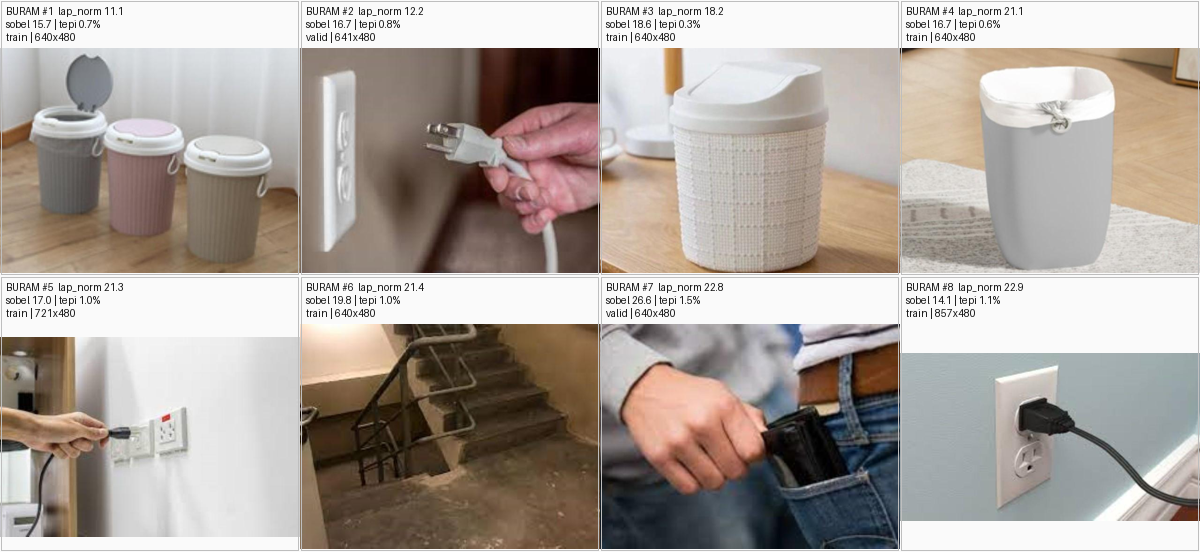

8 TERGELAP (brightness):
   26.7  kontras= 26.4  lap_norm=  61.2  test/347_jpg.rf.46f23088a17da2239cb4fe9d3184a2e0.jpg
   27.1  kontras= 35.2  lap_norm= 294.4  test/336_jpg.rf.41a95f7e650e89223b1d192e9afb2023.jpg
   30.1  kontras= 52.2  lap_norm= 429.7  test/326_jpg.rf.46112df88ebfd485f060728181016ab2.jpg
   30.3  kontras= 38.7  lap_norm= 449.4  test/335_jpeg.rf.2018a604fe9af2e499e4df6898308fb1.jpg
   33.2  kontras= 53.8  lap_norm= 410.2  test/332_jpg.rf.961843a1aaa304a4b3592f4aa1c3693d.jpg
   35.8  kontras= 62.8  lap_norm= 153.2  test/337_jpg.rf.17a47814697cc4034131b3d3a1997e7e.jpg
   37.9  kontras= 44.5  lap_norm=  59.7  test/334_png.rf.fd93edb0af1c0ce81afe2f4094f49b3e.jpg
   38.8  kontras= 42.0  lap_norm= 167.7  test/322_jpg.rf.3e947ec1530cef0ea6a6ad80f092b22b.jpg

8 TERBURAM (lap_norm setelah resize 640x480):
  lap_norm=  11.1  sobel=15.71  tepi= 0.7%  train/182169547_jpg.rf.3d3d40f6991bde8b3e04cee5687f8936.jpg
  lap_norm=  12.2  sobel=16.68  tepi= 0.8%  valid/182169177_jpg.rf.2b84

In [32]:
print("8 gambar dengan detail terendah (lap_norm):")
display(montage(blur, t_blur))

print("8 TERGELAP (brightness):")
for r in dark:
    print(f"  {r['brightness']:5.1f}  kontras={r['contrast']:5.1f}  lap_norm={r['lap_norm']:6.1f}  "
          f"{r['split']}/{r['file_name']}")
print("\n8 TERBURAM (lap_norm setelah resize 640x480):")
for r in blur:
    print(f"  lap_norm={r['lap_norm']:6.1f}  sobel={r['sobel']:5.2f}  tepi={r['edge_pct']:4.1f}%  "
          f"{r['split']}/{r['file_name']}")

### 11.1 Delapan gambar tergelap

**Isi gambar:** semuanya interior bergaya sinematik dengan pencahayaan sangat
rendah — ruangan remang, backlight dari jendela, satu frame berisi siluet orang
di meja, satu frame sunset dari dalam ruangan.

**Temuan:** kedelapan gambar tergelap **seluruhnya berasal dari split `test`**.
Ini bukti tambahan bahwa test adalah populasi berbeda (fotografi interior
artistik vs foto kamar biasa di train). Konsekuensi: model yang dilatih pada
train tidak pernah melihat kondisi pencahayaan ekstrem, sehingga penurunan skor
di test sebagian berasal dari *lighting shift*, bukan dari domain ruangan.

### 11.2 Delapan gambar dengan detail terendah

**Isi gambar:** tempat sampah di latar polos, steker dan colokan di dinding
putih, tangan memasukkan dompet ke saku, tangga beton.

**Temuan penting — ini bukan blur.** Setelah diperiksa, kedelapan gambar
**tajam**; nilai rendah muncul karena latar luas yang seragam (dinding putih,
permukaan polos) sehingga tidak ada tepi untuk dideteksi. Bukti pendukung:
`edge_pct` 0,3–1,5% vs median dataset 4,92%. Jadi metrik Laplacian variance di
sini mengukur **kelangkaan tekstur**, bukan ketajaman fokus.

**Konsekuensi metodologis:** jangan pakai `blur_var` mentah untuk menyaring
data. Kalau perlu filter kualitas, kombinasikan dengan `sobel` dan `edge_pct`,
lalu verifikasi visual.

**Kesimpulan:** dataset tidak punya masalah blur. Yang dimilikinya adalah
(a) subpopulasi foto objek berlatar polos di train/valid, dan (b) subpopulasi
interior gelap sinematik yang eksklusif di test. Keduanya memperlebar jarak
train→test di luar faktor arsitektur model.

## 12. Ikhtisar distribusi

Empat panel: 25 kelas terbanyak, instance per gambar, log luas mask relatif, dan
kecerahan.

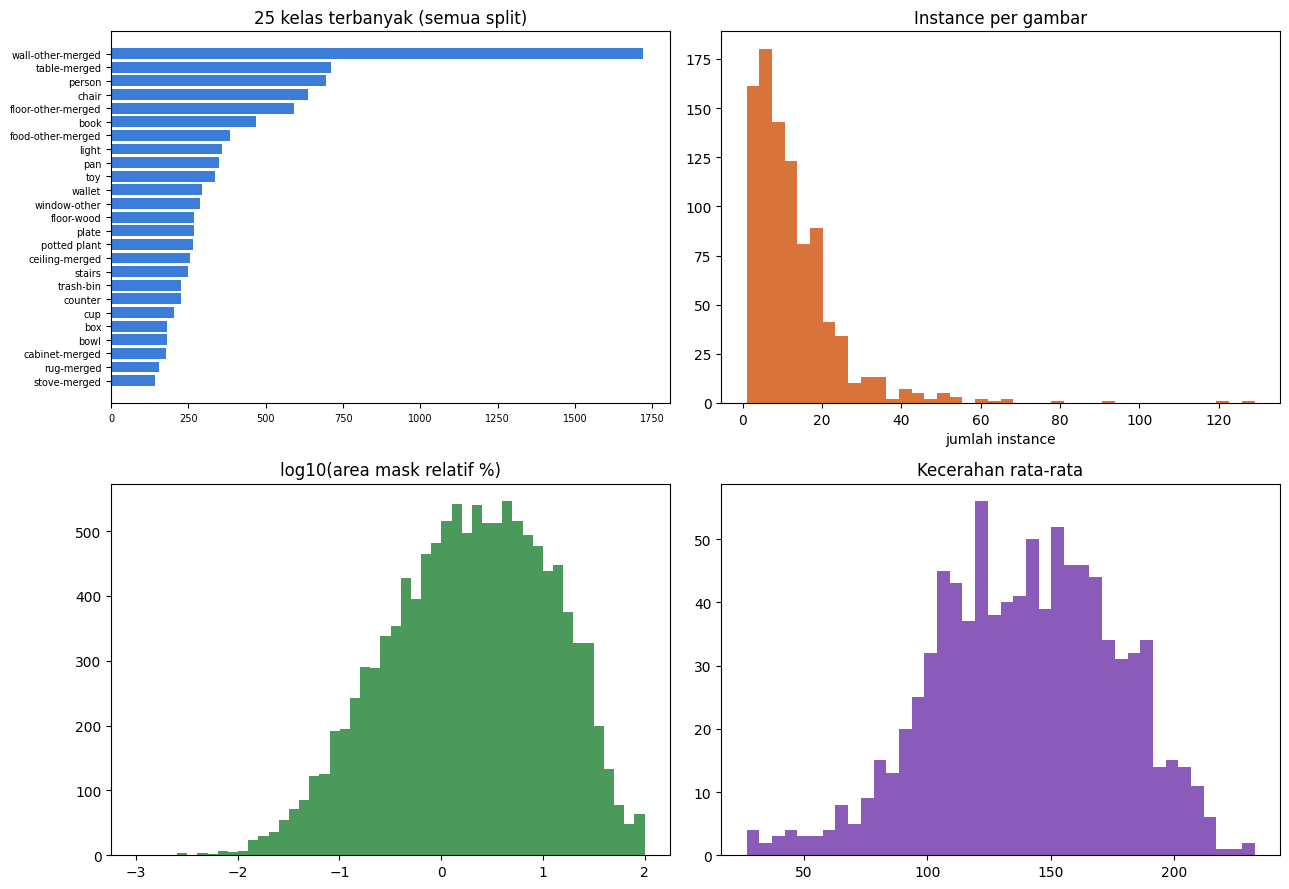

In [33]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
top = cls[cls["total"] > 0].head(25)["total"][::-1]
ax[0, 0].barh(top.index, top.values, color="#3b7dd8")
ax[0, 0].set_title("25 kelas terbanyak (semua split)")
ax[0, 0].tick_params(labelsize=7)
ax[0, 1].hist(per_img.values, bins=40, color="#d8743b")
ax[0, 1].set_title("Instance per gambar")
ax[0, 1].set_xlabel("jumlah instance")
ax[1, 0].hist(np.log10(anns.rel_mask.clip(1e-6, 1) * 100), bins=50, color="#4c9a5b")
ax[1, 0].set_title("log10(area mask relatif %)")
ax[1, 1].hist(imgs.brightness, bins=40, color="#8a5bb8")
ax[1, 1].set_title("Kecerahan rata-rata")
fig.tight_layout()
plt.show()

## 13. Tabel ringkas di memori

Semua tabel yang dipakai di notebook ini hidup sebagai DataFrame di memori.
Tidak ada berkas yang ditulis. Kalau suatu saat tabel ini perlu dipakai skrip
lain, cukup `imgs.to_csv(...)` di sel tambahan — bukan bagian dari notebook ini.

In [34]:
ringkas = pd.DataFrame([
    ("imgs", "per gambar: split, resolusi, ukuran, brightness, kontras, blur, EXIF", len(imgs)),
    ("anns", "per anotasi: kategori, bbox, luas mask relatif, bucket ukuran", len(anns)),
    ("cls", "matriks kelas x split + total", len(cls)),
    ("cons_df", "ringkasan integritas per split", len(cons_df)),
    ("near", "pasangan near-duplicate + jarak Hamming", len(near)),
    ("nm", "metrik blur ternormalisasi pada kanvas 640x480", len(nm)),
], columns=["variabel", "isi", "baris"])
print(ringkas.to_string(index=False))
print()
print("Tidak ada berkas yang ditulis ke disk oleh notebook ini.")

variabel                                                                  isi  baris
    imgs per gambar: split, resolusi, ukuran, brightness, kontras, blur, EXIF    922
    anns        per anotasi: kategori, bbox, luas mask relatif, bucket ukuran  11845
     cls                                        matriks kelas x split + total     75
 cons_df                                       ringkasan integritas per split      3
    near                              pasangan near-duplicate + jarak Hamming     10
      nm                       metrik blur ternormalisasi pada kanvas 640x480    922

Tidak ada berkas yang ditulis ke disk oleh notebook ini.
